In [1]:
import matplotlib.pyplot as plt
import math
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association


PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"
CLASS_COLOURS = (PLOT_BLUE, PLOT_ORANGE)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)  # For reproducibility
FIGSIZE = (6, 5)

raw_train = pd.read_csv('../data/raw/train.csv', index_col="ID")
raw_clientes = pd.read_csv('../data/raw/clientes.csv', index_col="customer_id")

# join keeps the ID index (pd.merge would reset it)
raw = raw_train.join(raw_clientes, on="customer_id")


# <font color='#E8800A'>Handling duplicates</font> <a class="anchor" id="dups"></a>

Done first, before any column is dropped: with fewer columns, different purchases can start to look identical.

In [2]:
raw = raw.drop_duplicates()

# <font color='#E8800A'>Missing values</font> <a class="anchor" id="missing"></a>

In [3]:
print(f"Total number of missing values: {raw.isna().sum().sum()}")

na_summary = pd.DataFrame({
    "NA_count": raw.isna().sum(),
    "NA_percentage": raw.isna().mean() * 100
})

print(na_summary.sort_values("NA_count", ascending=False))

Total number of missing values: 24924
                                NA_count  NA_percentage
customer_type                       6524     100.000000
street                              3831      58.721643
island                              2207      33.828939
city                                2149      32.939914
prior_std_gap_days                  1468      22.501533
prior_mean_gap_days                 1298      19.895769
prior_std_purchase_value            1103      16.906806
prior_mean_purchase_value            852      13.059473
days_since_previous_purchase         851      13.044145
prior_min_purchase_value             658      10.085837
prior_max_purchase_value             658      10.085837
postal_area                          278       4.261189
transport_method                     251       3.847333
spend_365d                           250       3.832005
payment_type                         250       3.832005
warehouse                            250       3.832005
salesperso

<Axes: title={'center': 'Missing Values by Feature'}, ylabel='Missing values (%)'>

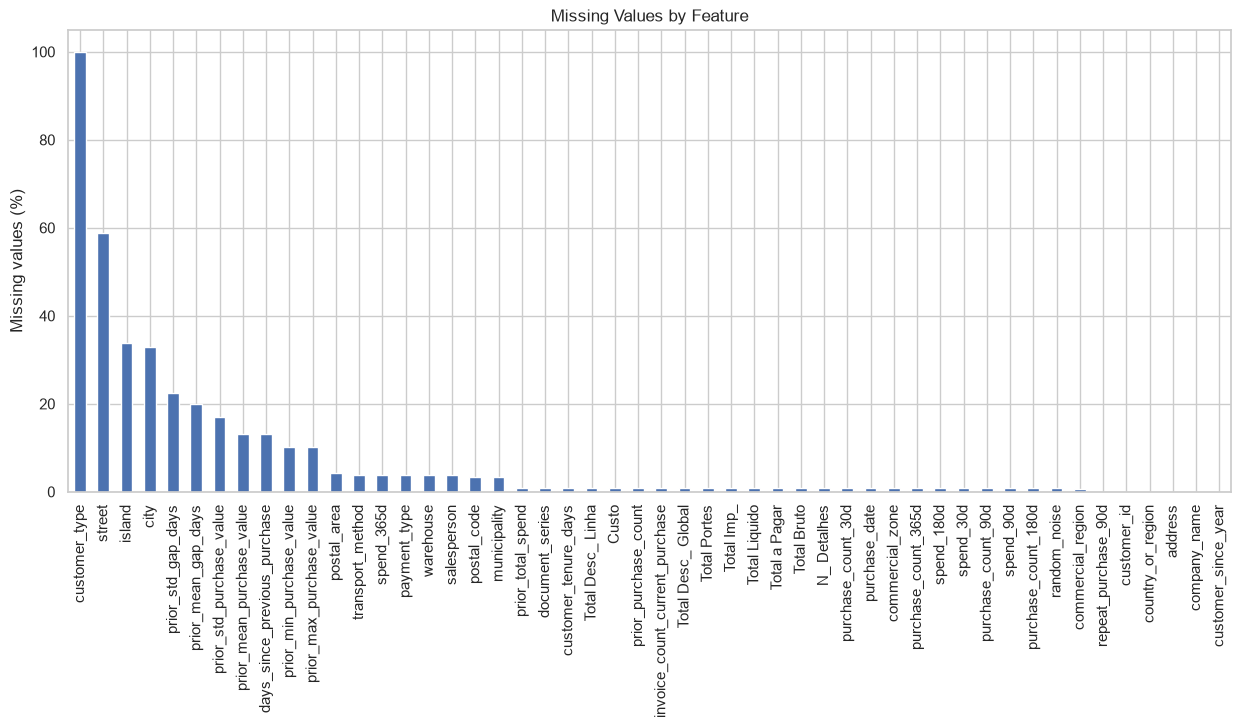

In [4]:
na_percentage = raw.isna().mean() * 100

na_percentage = na_percentage.sort_values(ascending=False)

na_percentage.plot(
    kind="bar",
    figsize=(15, 6),
    ylabel="Missing values (%)",
    title="Missing Values by Feature"
)

In [5]:
target = "repeat_purchase_90d"

rows = []

# Do not test the target itself as a predictor
features = [column for column in raw.columns if column != target]

for column in features:
    missing_flag = raw[column].isna()

    table = pd.crosstab(
        missing_flag,
        raw[target],
        dropna=False,
    )

    # Cramér's V and chi-square are undefined when there is
    # no variation in the missingness flag or target.
    if table.shape[0] < 2 or table.shape[1] < 2:
        rows.append({
            "feature": column,
            "missing_count": int(missing_flag.sum()),
            "missing_percentage": 100 * missing_flag.mean(),
            "chi2": np.nan,
            "p": np.nan,
            "Cramer's V": np.nan,
            "min expected count": np.nan,
        })
        continue

    chi2, p, _, expected = chi2_contingency(table)

    rows.append({
        "feature": column,
        "missing_count": int(missing_flag.sum()),
        "missing_percentage": 100 * missing_flag.mean(),
        "chi2": chi2,
        "p": p,
        "Cramer's V": association(
            table,
            method="cramer",
            correction=True,
        ),
        "min expected count": expected.min(),
    })

missing_target_table = (
    pd.DataFrame(rows)
    .sort_values(
        ["p", "Cramer's V"],
        ascending=[True, False],
        na_position="last",
    )
    .reset_index(drop=True)
)

missing_target_table

,feature,missing_count,missing_percentage,chi2,p,Cramer's V,min expected count
0,prior_std_gap_days,1468,22.501533,283.341096,1.404522e-63,0.208400,647.594114
1,prior_std_purchase_value,1103,16.906806,221.908292,3.468522e-50,0.184429,486.577866
2,prior_mean_gap_days,1298,19.895769,163.784645,1.685806e-37,0.158445,572.600245
3,prior_min_purchase_value,658,10.085837,136.747059,1.369666e-31,0.144778,290.270386
4,prior_max_purchase_value,658,10.085837,136.747059,1.369666e-31,0.144778,290.270386
5,days_since_previous_purchase,851,13.044145,106.042718,7.216273e-25,0.127492,375.410484
6,prior_mean_purchase_value,852,13.059473,102.250992,4.891446e-24,0.125192,375.851625
7,island,2207,33.828939,87.110761,1.026107e-20,0.115552,973.596873
8,street,3831,58.721643,29.646584,5.184392e-08,0.067411,1187.991110
9,municipality,217,3.326180,27.586972,1.501869e-07,0.065027,95.727468


# <font color='#E8800A'>Dropping features</font> <a class="anchor" id="drop_feat"></a>

In [6]:
# Decided in the exploration notebook:
# - customer_type is empty, random_noise is noise, customer_id is an identifier
# - the rest have one value per customer, so they identify the customer
#   rather than tell us anything new (chi-square with one purchase per customer)
columns_to_drop = [
    "customer_type",
    "random_noise",
    "customer_id",
    "company_name",
    "address",
    "postal_code",
    "street",
    "city",
    "postal_area",
    "municipality",
]

In [7]:
raw = raw.drop(columns=columns_to_drop)

In [8]:
raw["purchase_date"] = pd.to_datetime(raw["purchase_date"], format="%Y-%m-%d")
raw.dtypes

Total a Pagar                            float64
Total Bruto                              float64
Total Liquido                            float64
Total Imp_                               float64
Total Portes                             float64
Total Desc_ Global                       float64
Total Desc_ Linha                        float64
Custo                                    float64
N_ Detalhes                              float64
invoice_count_current_purchase           float64
repeat_purchase_90d                        int64
days_since_previous_purchase             float64
customer_tenure_days                     float64
prior_purchase_count                     float64
prior_total_spend                        float64
prior_mean_purchase_value                float64
prior_std_purchase_value                 float64
prior_min_purchase_value                 float64
prior_max_purchase_value                 float64
prior_mean_gap_days                      float64
prior_std_gap_days  

In [9]:
pd.options.display.max_columns = None
raw.head(5)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,country_or_region,commercial_region,island,customer_since_year
ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,1,79.0,126.0,2.0,858.30,429.150000,112.656252,349.49,508.81,47.000000,NaN,0.0,0.00,1.0,349.49,2.0,858.30,2.0,858.30,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,Country CT10: Land of The Final Version,Region RG25: We Will See Later,NaN,2024
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,1,244.0,616.0,5.0,6722.83,1344.566000,1683.795178,84.38,4222.15,93.000000,117.657696,0.0,0.00,0.0,0.00,0.0,0.00,4.0,2500.68,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,2015
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,1,9.0,610.0,90.0,17590.08,195.445333,190.389932,4.54,1002.15,6.752809,6.384073,2.0,111.27,9.0,1928.55,28.0,5290.25,49.0,7899.80,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,Country CT10: Land of The Final Version,Region RG23: We Will See Later,NaN,2017
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,0,97.0,97.0,1.0,270.33,270.330000,NaN,270.33,270.33,NaN,NaN,0.0,0.00,0.0,0.00,1.0,270.33,1.0,270.33,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,2018
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,1,85.0,1575.0,25.0,12803.02,512.120800,406.696963,22.58,1736.74,62.083333,66.246520,0.0,0.00,2.0,184.13,4.0,2062.50,4.0,2062.50,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,Country CT10: Land of The Final Version,Region RG31: We Will See Later,NaN,2017


# <font color='#E8800A'>Invalid values</font> <a class="anchor" id="invalid"></a>

Negative amounts and durations can't be real, and neither can the 1,000,000,000 in `prior_mean_purchase_value` and `spend_365d` (a placeholder code). They are set to NaN, so they get imputed like any other missing value.

In [10]:
numeric_columns = raw.select_dtypes(include="number").columns.drop(target)

invalid = (raw[numeric_columns] < 0) | (raw[numeric_columns] == 1e9)
print("invalid values per column:")
print(invalid.sum()[invalid.sum() > 0])

raw[numeric_columns] = raw[numeric_columns].mask(invalid)

invalid values per column:
days_since_previous_purchase    16
prior_mean_purchase_value       32
prior_mean_gap_days             16
spend_365d                      30
dtype: int64


# <font color='#E8800A'>Splitting by time</font> <a class="anchor" id="split"></a>

`test.csv` is entirely later than `train.csv` (train ends in 2025-02, test runs from 2025-05 to 2026-10). A random split would mix old and new purchases of the same customer and give a validation score that looks better than it really is. So the validation set is the **most recent 20%** of purchases.

In [11]:
# The rows that are empty in 24 columns have no purchase_date either, so they
# can't be placed in time, and they hold no information: drop them.
# (There were 65; the 10 duplicates dropped earlier were all among them.)
print(f"rows without a purchase_date dropped: {raw['purchase_date'].isna().sum()}")
raw = raw.dropna(subset=["purchase_date"])

raw = raw.sort_values("purchase_date")
cutoff = int(len(raw) * 0.8)

X = raw.drop(columns=[target])
y = raw[target]

X_train, X_val = X.iloc[:cutoff], X.iloc[cutoff:]
y_train, y_val = y.iloc[:cutoff], y.iloc[cutoff:]

print(f"Training:   {X_train.shape}, {X_train['purchase_date'].min():%Y-%m-%d} to {X_train['purchase_date'].max():%Y-%m-%d}, repeat rate {y_train.mean():.2f}")
print(f"Validation: {X_val.shape}, {X_val['purchase_date'].min():%Y-%m-%d} to {X_val['purchase_date'].max():%Y-%m-%d}, repeat rate {y_val.mean():.2f}")

rows without a purchase_date dropped: 55
Training:   (5175, 39), 2015-07-11 to 2023-06-17, repeat rate 0.55
Validation: (1294, 39), 2023-06-17 to 2025-02-15, repeat rate 0.61


# <font color='#E8800A'>Imputing</font> <a class="anchor" id="imputing"></a>

# <font color='#E8800A'>Encoding</font> <a class="anchor" id="encoding"></a>

# <font color='#E8800A'>Outliers</font> <a class="anchor" id="outliers"></a>